In [3]:
import numpy as np

In [4]:
Ej=1
Ecc=1
ng=0.3
n1=0
n2=1

In [5]:
N=n2-n1+1

In [6]:
Hdash=np.zeros(N*N).reshape((N,N))
Eav=Ecc*ng*ng-Ecc*ng+Ecc/2

In [7]:
for i in range(N):
    for j in range(N):
        if(i==j):
            Hdash[i,j]=Ecc*(i+n1-ng)**2-Eav
        if(i==j+1):
            Hdash[i,j]=-Ej/2
        if(i==j-1):
            Hdash[i,j]=-Ej/2

Hdash

evalue,evector=np.linalg.eig(Hdash)
idx=evalue.argsort()
evalue=evalue[idx]
evector=evector[:,idx]

In [8]:
evalue
evector

array([[-0.82806723,  0.56062881],
       [-0.56062881, -0.82806723]])

In [9]:
from Diagonalization import Diagonalization

In [10]:
Diagonalization(1,1,0.3,0,1)

(array([-0.53851648,  0.53851648]),
 array([[-0.82806723, -0.56062881],
        [ 0.56062881, -0.82806723]]))

In [131]:
EJ=1
ECC=0.02
ng=0
ng0=0
N1=-100
N2=100
ng_range=0.5
discretization=100

In [132]:
E0=[]
E1=[]
E2=[]
for i in range(0,2*discretization+1,1):
    eigenvalues, eigenvectors=Diagonalization\
        (EJ,ECC,ng0-ng_range+2*ng_range*i/2/discretization+0.5,N1,N2)
    E0.append(eigenvalues[0])
    E1.append(eigenvalues[1])
    E2.append(eigenvalues[2])
    

In [101]:
import matplotlib.pyplot as plt

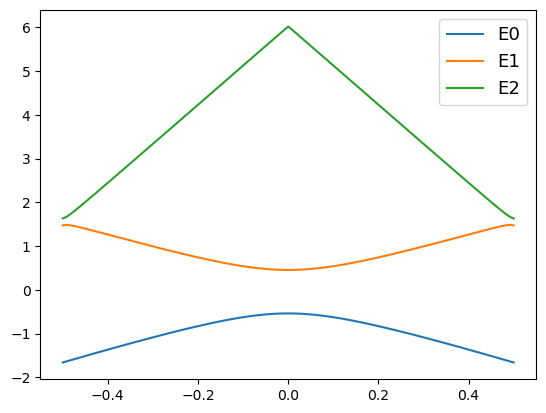

In [102]:
plt.plot(np.linspace(ng0-ng_range,ng0+ng_range,2*discretization+1),E0)
plt.plot(np.linspace(ng0-ng_range,ng0+ng_range,2*discretization+1),E1)
plt.plot(np.linspace(ng0-ng_range,ng0+ng_range,2*discretization+1),E2)
plt.legend(["E0","E1","E2"],fontsize=13)

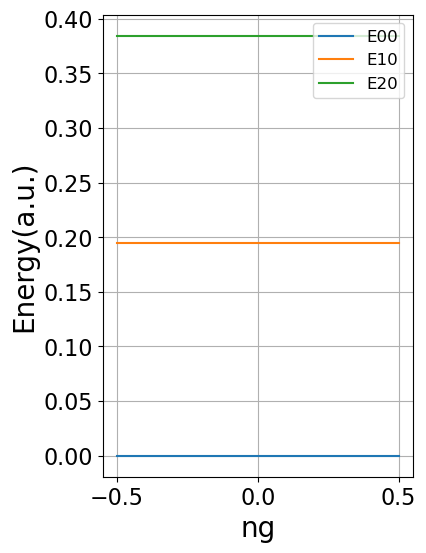

In [133]:
import matplotlib.ticker as ticker

fig, ax=plt.subplots(figsize=(4,6))

ax.plot(np.linspace(ng0-ng_range,ng0+ng_range, 2*discretization+1),\
         np.array(E0)-np.array(E0),label='E00')
ax.plot(np.linspace(ng0-ng_range,ng0+ng_range, 2*discretization+1),\
         np.array(E1)-np.array(E0),label='E10')
ax.plot(np.linspace(ng0-ng_range,ng0+ng_range, 2*discretization+1),\
         np.array(E2)-np.array(E0),label='E20')

ax.xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:.1f}'))

ax.set_xlabel('ng',fontsize=20)
ax.set_ylabel('Energy(a.u.)',fontsize=20)
ax.tick_params(axis='both', labelsize=16)
ax.legend(loc='upper right',fontsize=12)
ax.grid()

In [104]:
#anharmonicity=E21-E10
ECC_range=0.5
ECC0=0.5
#ng=0.5
ng0=0
E0=[]
E1=[]
E2=[]
for i in range(0,2*discretization+1,1):
    eigenvalues, eigenvectors=Diagonalization\
        (EJ,ECC0-ECC_range+ECC_range*i/discretization,ng0,N1,N2)
    E0.append(eigenvalues[0])
    E1.append(eigenvalues[1])
    E2.append(eigenvalues[2])

E10=np.array(E1)-np.array(E0)
E21=np.array(E2)-np.array(E1)

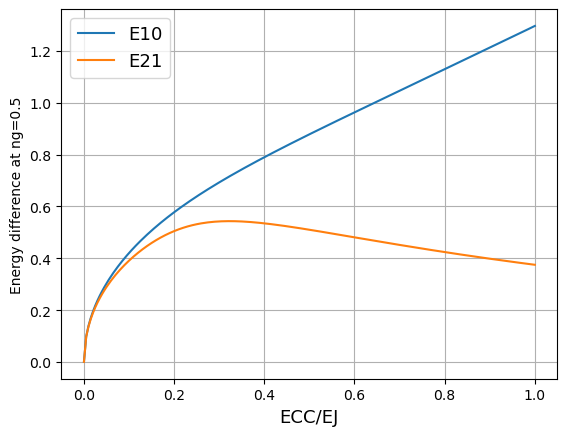

In [105]:
plt.plot(np.linspace(-ECC_range+ECC0,ECC0+ECC_range, 2*discretization+1),\
         E10)
plt.plot(np.linspace(-ECC_range+ECC0,ECC0+ECC_range, 2*discretization+1),\
         E21)

plt.xlabel('ECC/EJ',fontsize=13)
plt.ylabel('Energy difference at ng=0.5')

plt.legend(["E10","E21"],fontsize=13)
plt.grid()

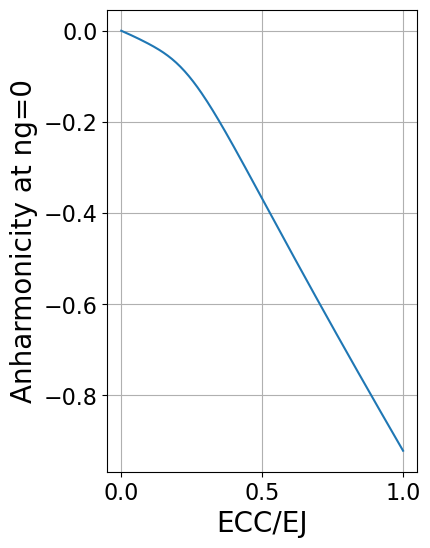

In [110]:
E2110=E21-E10

import matplotlib.ticker as ticker
fig, ax=plt.subplots(figsize=(4,6))


ax.plot(np.linspace(-ECC_range+ECC0,ECC0+ECC_range, 2*discretization+1),\
         E2110)

ax.set_xlabel('ECC/EJ',fontsize=20)
ax.set_ylabel(f'Anharmonicity at ng={ng0}',fontsize=20)
ax.tick_params(axis='both', labelsize=16)

ax.grid()

In [ ]:
#ng dependence=E10''(ng=ng0)
E0=[]
E1=[]
ng0=0
E10=[]
interval=0.01
for i in range(0,3,1):
    eigenvalues, eigenvectors=Diagonalization\
        (EJ,ECC,ng0+i*interval,N1,N2)
    E0.append(eigenvalues[0])
    E1.append(eigenvalues[1])
    
E10=np.array(E1)-np.array(E0)
E10

E102nd=(E10[2]+E10[0]-2*E10[1])/interval**2
#E102nd

In [112]:
#ng dependence=E10''(ng=ng0) OVER ECC range
ECC0=0.5
ECC_range=0.5
E102nd=[]
interval=0.01

for i in range(0,2*discretization+1,1):
    E0=[]
    E1=[]
    E10=[]
    for j in range(0,3,1):
        eigenvalues, eigenvectors=Diagonalization\
            (EJ,ECC0-ECC_range+ECC_range*i/discretization,ng0+j*interval,N1,N2)
        E0.append(eigenvalues[0])
        E1.append(eigenvalues[1])
    E10=np.array(E1)-np.array(E0)
    E102nd.append((E10[2]+E10[0]-2*E10[1])/interval**2)

#E102nd

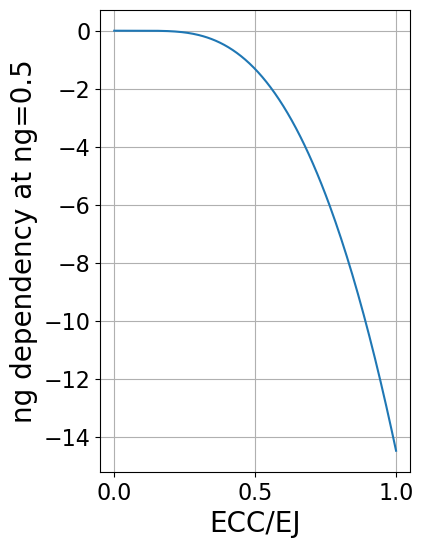

In [119]:
import matplotlib.ticker as ticker
fig, ax=plt.subplots(figsize=(4,6))



ax.plot(np.linspace(-ECC_range+ECC0,ECC0+ECC_range, 2*discretization+1),\
         E102nd)

ax.set_xlabel('ECC/EJ',fontsize=20)
ax.set_ylabel('ng dependency at ng=0.5',fontsize=20)
ax.tick_params(axis='both', labelsize=16)

#plt.legend(["E10","E21"],fontsize=13)
ax.grid()

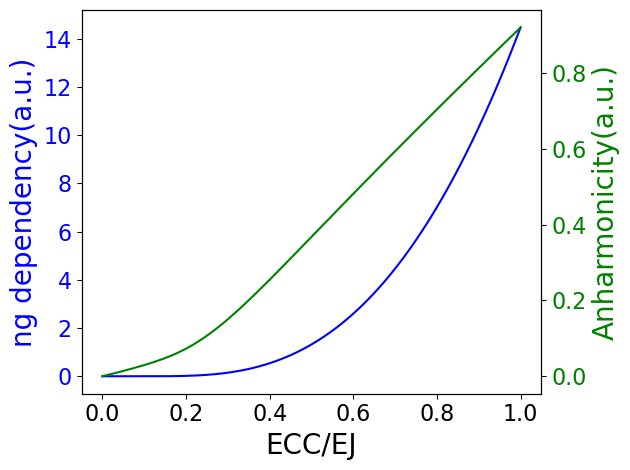

In [134]:
import matplotlib.pyplot as plt
import numpy as np

# 1. 데이터 준비
x = np.linspace(-ECC_range+ECC0,ECC0+ECC_range, 2*discretization+1)
y1 = np.array(E102nd)*(-1)          # 왼쪽 Y축: 기하급수적으로 증가하는 데이터 (범위: 약 2 ~ 22000)
y2 = E2110             # 오른쪽 Y축: 선형으로 증가하는 데이터 (범위: 10 ~ 100)

# 2. 첫 번째 그래프 (왼쪽 Y축) 생성
fig, ax1 = plt.subplots()

ax1.plot(x, y1, color='blue', label='Linear')
ax1.set_xlabel('ECC/EJ',fontsize=20)
ax1.set_ylabel('ng dependency(a.u.)', color='blue',fontsize=20)
ax1.tick_params(axis='y', labelcolor='blue',labelsize=16)  # Y축 눈금 색상 맞추기
ax1.tick_params(axis='x',labelsize=16)

# 3. 두 번째 그래프 (오른쪽 Y축) 생성: X축을 공유하는 twinx() 사용
ax2 = ax1.twinx()
ax2.plot(x, -y2, color='green', label='Linear')
ax2.set_ylabel('Anharmonicity(a.u.)',\
     color='green',fontsize=20)
ax2.tick_params(axis='y', labelcolor='green',labelsize=16)  # Y축 눈금 색상 맞추기

# 4. 레이아웃 정리 및 출력
fig.tight_layout()
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. 데이터 준비
x = np.linspace(-ECC_range+ECC0,ECC0+ECC_range, 2*discretization+1)
y1 = E102nd             # 왼쪽 Y축: 기하급수적으로 증가하는 데이터 (범위: 약 2 ~ 22000)
y2 = E2110             # 오른쪽 Y축: 선형으로 증가하는 데이터 (범위: 10 ~ 100)

# 2. 첫 번째 그래프 (왼쪽 Y축) 생성
fig, ax1 = plt.subplots()

ax1.plot(x, y1, color='blue', label='Linear')
ax1.set_xlabel('ECC/EJ')
ax1.set_ylabel('ng dependency at ng=0', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')  # Y축 눈금 색상 맞추기

# 3. 두 번째 그래프 (오른쪽 Y축) 생성: X축을 공유하는 twinx() 사용
ax2 = ax1.twinx()
ax2.plot(x, y2, color='green', label='Linear')
ax2.set_ylabel('Anharmonicity(E21-E10)', color='green')
ax2.tick_params(axis='y', labelcolor='green')  # Y축 눈금 색상 맞추기

# 4. 레이아웃 정리 및 출력
fig.tight_layout()
plt.show()
